# Cuaderno práctico: SVM en la práctica
**EST852 Machine Learning · sesión de 120 minutos**

| Parte | Bloque | Tiempo de práctica | Datos |
|---|---|---|---|
| 0 | Retomada | 4 min | lunas |
| 1A | Impacto de C, γ y kernel | 15 min | lunas (2 variables, se puede dibujar) |
| 1B | Escala y parámetros con más variables | 10 min | *breast cancer* |
| 2 | Métricas, umbral y `class_weight` | 15 min | *breast cancer* |
| 3 | Validación y selección de modelo | 20 min | *breast cancer* |

**Cómo trabajar.** En cada parte: (1) escribe tu **predicción** antes de ejecutar; (2) ejecuta; (3) cambia los valores marcados con `# <-- CAMBIA` y vuelve a ejecutar; (4) responde la pregunta de **reflexión**. Las semillas son fijas para que todos obtengan lo mismo.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import make_moons, load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, classification_report, precision_score,
                             recall_score, f1_score, accuracy_score, ConfusionMatrixDisplay)

SEMILLA = 0
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

## Parte 0. Retomada (4 min)
La sesión anterior terminó con un ejemplo de clasificación no lineal. Lo reproducimos: dos lunas con ruido y una SVM con kernel RBF.

**Predicción.** ¿Podría un kernel lineal separar estas clases? ¿Cuántos vectores soporte esperas?

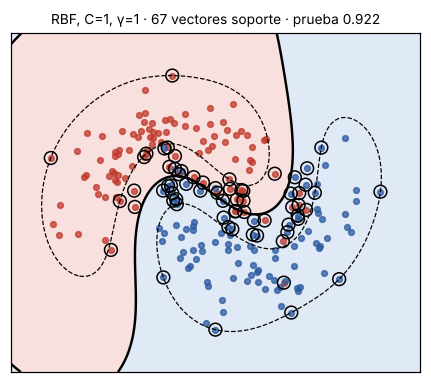

In [2]:
X2, y2 = make_moons(300, noise=0.3, random_state=SEMILLA)
X2tr, X2te, y2tr, y2te = train_test_split(X2, y2, test_size=0.3, stratify=y2, random_state=SEMILLA)

def dibujar(ax, modelo, X, y, titulo):
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min()-.5, X[:, 0].max()+.5, 250),
                         np.linspace(X[:, 1].min()-.5, X[:, 1].max()+.5, 250))
    f = modelo.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, f, levels=[-99, 0, 99], colors=['#f4c7c3', '#c8d8f0'], alpha=.55)
    ax.contour(gx, gy, f, levels=[0], colors='k', linewidths=1.6)
    ax.contour(gx, gy, f, levels=[-1, 1], colors='k', linewidths=.8, linestyles='--')
    for c, col in [(0, '#c0392b'), (1, '#2c5aa0')]:
        ax.scatter(*X[y == c].T, s=14, c=col, alpha=.75)
    ax.scatter(*modelo.support_vectors_.T, s=70, facecolors='none', edgecolors='k', linewidths=1)
    ax.set_title(titulo, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

m = SVC(kernel='rbf', C=1, gamma=1).fit(X2tr, y2tr)
fig, ax = plt.subplots(figsize=(4.8, 4))
dibujar(ax, m, X2tr, y2tr, f'RBF, C=1, γ=1 · {m.n_support_.sum()} vectores soporte · prueba {m.score(X2te, y2te):.3f}')
plt.show()

**Reflexión (1 min).** En el gráfico, ¿qué representan la línea continua, las punteadas y los círculos? Si no lo recuerdas, es el momento de preguntar.

## Parte 1A. Impacto de los parámetros y del kernel (15 min)
**Objetivo.** Ver, en un caso que se puede dibujar, cómo cambian la frontera, el margen y el número de vectores soporte.

### 1A-1. El kernel
**Predicción.** Con las mismas lunas, ¿cuál kernel tendrá la frontera más parecida a la forma de las clases: lineal, polinomial de grado 3 o RBF?

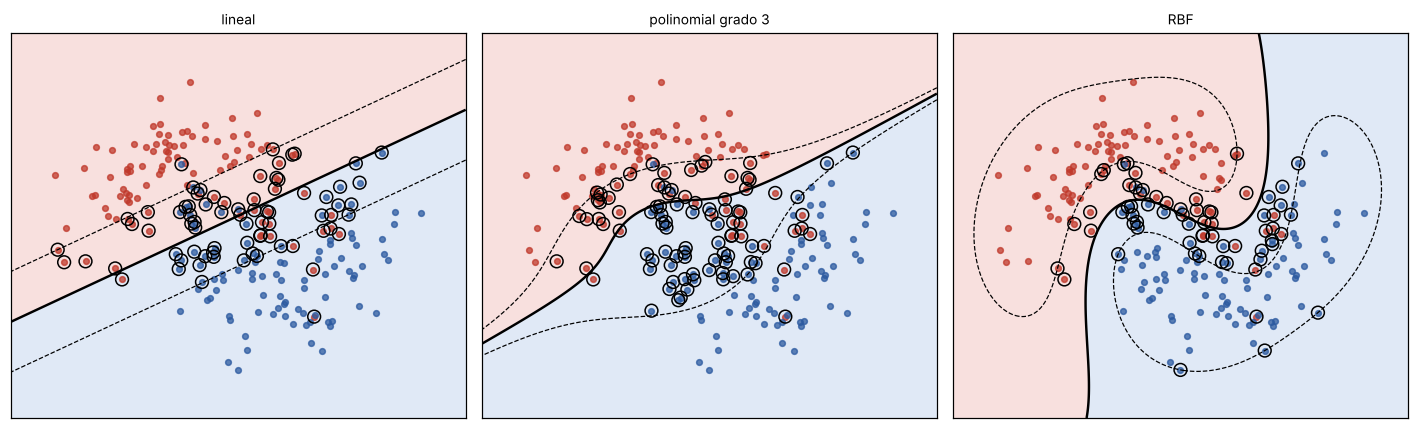

,vectores soporte,exactitud entrenamiento,exactitud prueba
lineal,76.0,0.857,0.767
polinomial grado 3,95.0,0.886,0.822
RBF,66.0,0.933,0.900


In [3]:
def resumen(modelo, Xtr, ytr, Xte, yte):
    return {'vectores soporte': int(modelo.n_support_.sum()),
            'exactitud entrenamiento': modelo.score(Xtr, ytr),
            'exactitud prueba': modelo.score(Xte, yte)}

configs = [('lineal', SVC(kernel='linear')),
           ('polinomial grado 3', SVC(kernel='poly', degree=3)),
           ('RBF', SVC(kernel='rbf'))]
fig, ejes = plt.subplots(1, 3, figsize=(13, 4))
filas = {}
for ax, (nombre, mod) in zip(ejes, configs):
    mod.fit(X2tr, y2tr); dibujar(ax, mod, X2tr, y2tr, nombre)
    filas[nombre] = resumen(mod, X2tr, y2tr, X2te, y2te)
plt.tight_layout(); plt.show()
pd.DataFrame(filas).T.round(3)

**Qué observar.** El lineal solo puede trazar una recta; el polinomial y el RBF curvan la frontera. Mira también cuánto cambian los vectores soporte.

### 1A-2. El parámetro C
**Predicción.** Con RBF y γ fijo, si C baja de 10 a 0,01, ¿el margen se ensancha o se angosta? ¿hay más o menos vectores soporte?

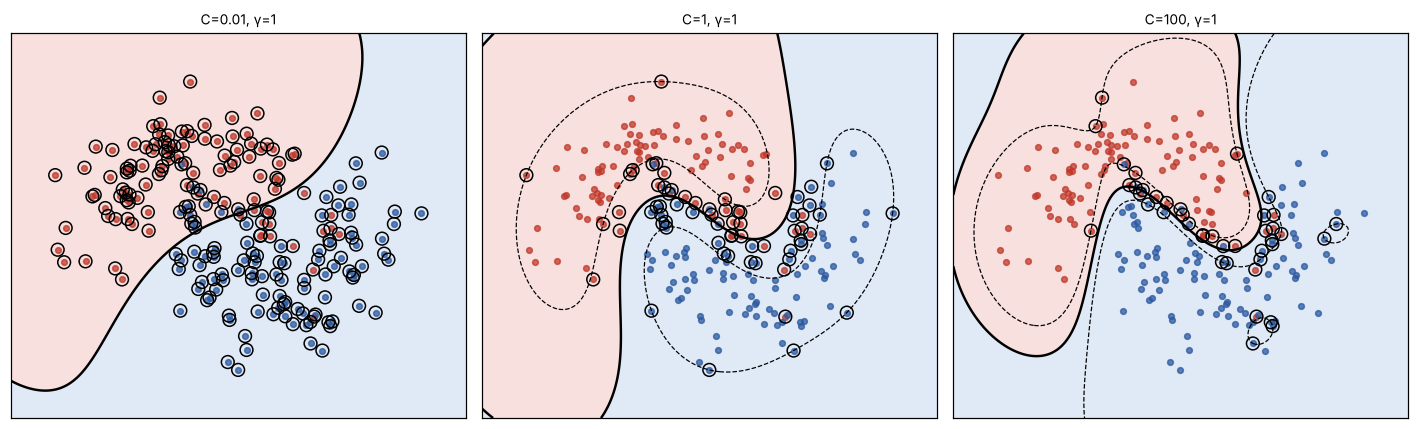

,vectores soporte,exactitud entrenamiento,exactitud prueba
C=0.01,210.0,0.857,0.767
C=1,67.0,0.933,0.922
C=100,41.0,0.938,0.944


In [4]:
GAMMA = 1                      # <-- CAMBIA (prueba 0.1 y 10)
Cs = [0.01, 1, 100]            # <-- CAMBIA
fig, ejes = plt.subplots(1, 3, figsize=(13, 4)); filas = {}
for ax, Cv in zip(ejes, Cs):
    mod = SVC(kernel='rbf', C=Cv, gamma=GAMMA).fit(X2tr, y2tr)
    dibujar(ax, mod, X2tr, y2tr, f'C={Cv}, γ={GAMMA}'); filas[f'C={Cv}'] = resumen(mod, X2tr, y2tr, X2te, y2te)
plt.tight_layout(); plt.show()
pd.DataFrame(filas).T.round(3)

**Qué observar.** Con C=0,01 todos los puntos de entrenamiento terminan siendo vectores soporte (210 de 210) y la frontera es casi lineal; con C=100 solo quedan 41. Recuerda: en scikit-learn, C grande penaliza más las violaciones del margen. Ojo: la prueba tiene solo 90 puntos, así que un punto equivale a 1,1 puntos de exactitud; la diferencia entre C=1 y C=100 en prueba no es concluyente.

### 1A-3. El parámetro γ
**Predicción.** Con C fijo, ¿qué pasa con la frontera y con la brecha entre exactitud de entrenamiento y de prueba cuando γ crece mucho?

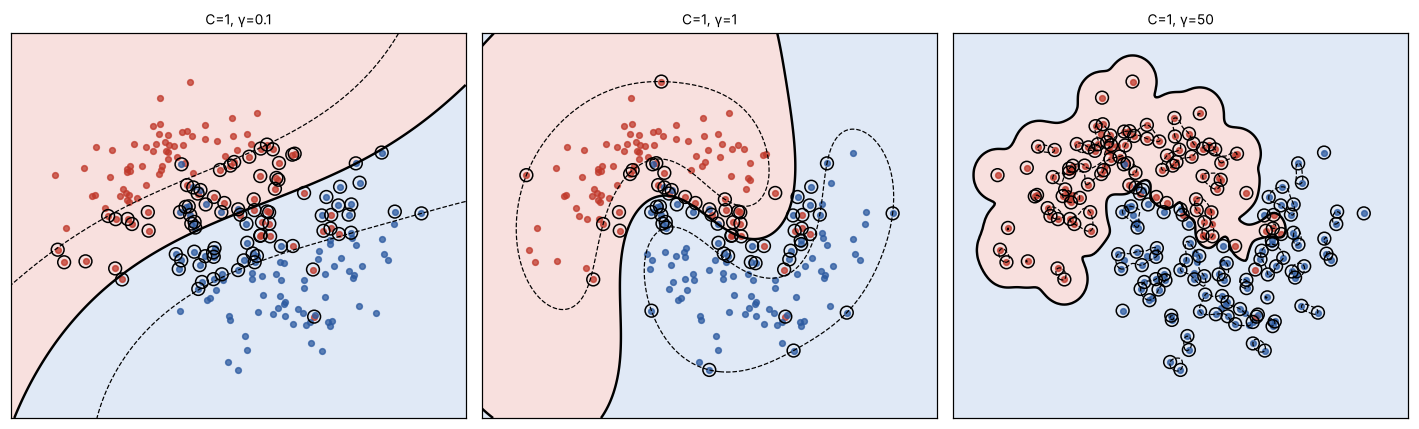

,vectores soporte,exactitud entrenamiento,exactitud prueba,brecha
γ=0.1,93.0,0.848,0.744,0.103
γ=1,67.0,0.933,0.922,0.011
γ=50,177.0,0.976,0.944,0.032


In [5]:
C_FIJO = 1                     # <-- CAMBIA
gammas = [0.1, 1, 50]          # <-- CAMBIA
fig, ejes = plt.subplots(1, 3, figsize=(13, 4)); filas = {}
for ax, g in zip(ejes, gammas):
    mod = SVC(kernel='rbf', C=C_FIJO, gamma=g).fit(X2tr, y2tr)
    dibujar(ax, mod, X2tr, y2tr, f'C={C_FIJO}, γ={g}'); filas[f'γ={g}'] = resumen(mod, X2tr, y2tr, X2te, y2te)
plt.tight_layout(); plt.show()
t = pd.DataFrame(filas).T; t['brecha'] = t['exactitud entrenamiento'] - t['exactitud prueba']
t.round(3)

**Qué observar (γ).** γ=0,1 subajusta (exactitud de entrenamiento 0,85); γ=50 sube el entrenamiento a 0,98 y los vectores soporte a 177, pero en prueba no empeora aquí. Con solo 90 casos de prueba eso no prueba que γ=50 sea bueno: es la razón de usar validación cruzada (Parte 3) y no una sola partición.

**Reflexión (3 min, en parejas).**
1. ¿Qué señales en la tabla indican sobreajuste (brecha entre entrenamiento y prueba, aumento de vectores soporte)? ¿Se ven con claridad aquí? ¿Por qué no?
2. Si γ es grande, ¿puede C compensarlo? Prueba γ=50 con C=0,01 y con C=100.
3. Con estos datos, ¿qué combinación elegirías a ojo y por qué *no* deberías decidir solo con la exactitud de entrenamiento?

## Parte 1B. Escala y parámetros con más variables (10 min)
**Objetivo.** Comprobar que en dimensión alta no se puede *ver* la frontera, y que la escala de las variables importa mucho para el RBF.

Usamos *breast cancer* (569 casos, 30 variables) con partición 70/30 estratificada.

In [6]:
datos = load_breast_cancer()
X, y = datos.data, datos.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
print('entrenamiento:', Xtr.shape, np.bincount(ytr), '| prueba:', Xte.shape, np.bincount(yte))
print(f'línea base (siempre la clase mayoritaria): {np.bincount(yte).max()/len(yte):.3f}')
pd.DataFrame(X, columns=datos.feature_names).describe().T[['min', 'max']].sort_values('max').iloc[[0, 1, -2, -1]]

entrenamiento: (398, 30) [148 250] | prueba: (171, 30) [ 64 107]
línea base (siempre la clase mayoritaria): 0.626


,min,max
fractal dimension error,0.000895,0.02984
smoothness error,0.001713,0.03113
mean area,143.500000,2501.00000
worst area,185.200000,4254.00000


### 1B-1. ¿Estandarizar importa?
**Predicción.** ¿En cuál kernel (lineal o RBF) crees que estandarizar mejora más? Anota un número para cada uno.

In [7]:
filas = []
for k in ['linear', 'rbf']:
    sin = SVC(kernel=k).fit(Xtr, ytr)
    con = make_pipeline(StandardScaler(), SVC(kernel=k)).fit(Xtr, ytr)
    filas.append({'kernel': k, 'sin estandarizar': sin.score(Xte, yte), 'estandarizado': con.score(Xte, yte)})
pd.DataFrame(filas).round(3)

,kernel,sin estandarizar,estandarizado
0,linear,0.942,0.953
1,rbf,0.906,0.953


**Qué observar.** El RBF depende de distancias; una variable de escala grande domina. Con 171 casos de prueba, 0,01 de diferencia son menos de 2 pacientes: no sobreinterpretes diferencias pequeñas.

### 1B-2. C y γ con 30 variables
Ya no podemos dibujar la frontera, así que usamos tres indicadores: vectores soporte, exactitud de entrenamiento y de prueba.

In [8]:
Gam = [0.001, 0.03, 1]         # <-- CAMBIA
filas = {}
for g in Gam:
    mod = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma=g)).fit(Xtr, ytr)
    filas[f'γ={g}'] = {'vectores soporte': int(mod[-1].n_support_.sum()),
                       'exactitud entrenamiento': mod.score(Xtr, ytr), 'exactitud prueba': mod.score(Xte, yte)}
pd.DataFrame(filas).T.round(3)

,vectores soporte,exactitud entrenamiento,exactitud prueba
γ=0.001,157.0,0.955,0.953
γ=0.03,95.0,0.992,0.953
γ=1,397.0,1.000,0.632


**Reflexión (2 min).** ¿Cómo se ve el sobreajuste cuando no se puede dibujar? Compara la exactitud de entrenamiento con la de prueba y con la línea base.

## Parte 2. Métricas de evaluación y ponderación de clases (15 min)
**Objetivo.** Ir más allá de la exactitud: medir cada tipo de error y actuar sobre él con el umbral y con `class_weight`.

En diagnóstico el error más costoso es un **falso negativo**: un tumor maligno clasificado como benigno. Para que la clase de interés sea la "positiva", definimos `1 = maligno`.

              precision    recall  f1-score   support

     benigno      0.963     0.963     0.963       107
     maligno      0.938     0.938     0.938        64

    accuracy                          0.953       171
   macro avg      0.950     0.950     0.950       171
weighted avg      0.953     0.953     0.953       171

verdaderos positivos=60  falsos negativos=4  falsos positivos=4  verdaderos negativos=103


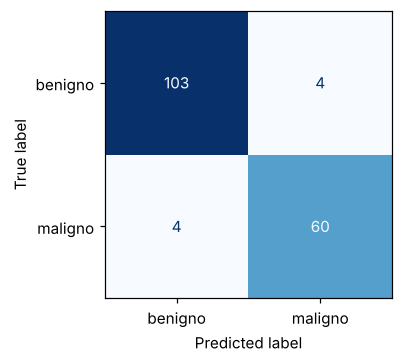

In [9]:
yb_tr, yb_te = (ytr == 0).astype(int), (yte == 0).astype(int)    # 1 = maligno
modelo = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma='scale')).fit(Xtr, yb_tr)
pred = modelo.predict(Xte)
print(classification_report(yb_te, pred, target_names=['benigno', 'maligno'], digits=3))
tn, fp, fn, tp = confusion_matrix(yb_te, pred).ravel()
print(f'verdaderos positivos={tp}  falsos negativos={fn}  falsos positivos={fp}  verdaderos negativos={tn}')
fig, ax = plt.subplots(figsize=(3.8, 3.4))
ConfusionMatrixDisplay(confusion_matrix(yb_te, pred), display_labels=['benigno', 'maligno']).plot(ax=ax, colorbar=False, cmap='Blues')
ax.grid(False); plt.tight_layout(); plt.show()

**Qué observar.** Precisión (de los que digo maligno, cuántos lo son) y *recall* (de los malignos, cuántos detecto) responden preguntas distintas. La exactitud mezcla ambas.

### 2-1. Mover el umbral
`decision_function` entrega f(x). Por defecto se clasifica "maligno" si f(x) > 0. Si bajamos el umbral, detectamos más malignos a costa de más falsos positivos.

**Predicción.** Si bajo el umbral de 0 a −0,5, ¿qué pasa con los falsos negativos? ¿y con los falsos positivos?

In [10]:
f = modelo.decision_function(Xte)
umbrales = [0.5, 0, -0.25, -0.5, -1]         # <-- CAMBIA
filas = []
for u in umbrales:
    p = (f > u).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb_te, p).ravel()
    filas.append({'umbral': u, 'falsos negativos': fn, 'falsos positivos': fp,
                  'recall maligno': recall_score(yb_te, p), 'precisión maligno': precision_score(yb_te, p), 'exactitud': accuracy_score(yb_te, p)})
pd.DataFrame(filas).round(3)

,umbral,falsos negativos,falsos positivos,recall maligno,precisión maligno,exactitud
0,0.50,10,0,0.844,1.000,0.942
1,0.00,4,4,0.938,0.938,0.953
2,-0.25,3,8,0.953,0.884,0.936
3,-0.50,2,11,0.969,0.849,0.924
4,-1.00,0,22,1.000,0.744,0.871


**Qué observar.** Con umbral 0 hay 4 falsos negativos y 4 falsos positivos; con umbral −0,5, 2 y 11; con −1, ningún falso negativo pero 22 falsos positivos. No hay umbral gratis: la elección depende del costo de cada error.

### 2-2. Ponderar las clases
`class_weight='balanced'` multiplica C por clase en proporción inversa a su frecuencia, así que equivocarse en la clase minoritaria "cuesta" más durante el entrenamiento.

**Predicción.** ¿Cuántos tumores malignos más detectará el modelo ponderado? ¿Qué costo tendrá?

In [11]:
filas = {}
for nombre, cw in [('sin ponderar', None), ('balanced', 'balanced'), ('maligno ×5', {0: 1, 1: 5})]:
    mod = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma='scale', class_weight=cw)).fit(Xtr, yb_tr)
    p = mod.predict(Xte); tn, fp, fn, tp = confusion_matrix(yb_te, p).ravel()
    filas[nombre] = {'falsos negativos': fn, 'falsos positivos': fp,
                     'recall maligno': recall_score(yb_te, p), 'precisión maligno': precision_score(yb_te, p), 'F1 maligno': f1_score(yb_te, p), 'exactitud': accuracy_score(yb_te, p)}
pd.DataFrame(filas).T.round(3)

,falsos negativos,falsos positivos,recall maligno,precisión maligno,F1 maligno,exactitud
sin ponderar,4.0,4.0,0.938,0.938,0.938,0.953
balanced,4.0,5.0,0.938,0.923,0.930,0.947
maligno ×5,2.0,6.0,0.969,0.912,0.939,0.953


**Qué observar (ponderación).** `balanced` no cambia los falsos negativos (4) y agrega un falso positivo; dar peso 5 a la clase maligna baja los falsos negativos de 4 a 2 y sube los falsos positivos de 4 a 6. El efecto es pequeño y comparable al de mover el umbral: con una sola partición de 171 casos no conviene sobreinterpretarlo.

**Reflexión (4 min).**
1. ¿Qué es más costoso aquí, un falso negativo o un falso positivo? ¿Cómo lo reflejas: con el umbral o con `class_weight`?
2. Con 171 casos de prueba, ¿un cambio de uno o dos pacientes es evidencia suficiente? ¿Qué harías para decidir con más seguridad?

## Parte 3. Validación y selección de modelo (20 min)
**Objetivo.** Elegir hiperparámetros **sin tocar el conjunto de prueba** y dar una estimación honesta del desempeño.

Regla: el preprocesamiento va **dentro de un `Pipeline`**, así se ajusta solo con los datos de entrenamiento de cada partición y no hay fuga de información.

### 3-1. Comparar con validación cruzada
**Predicción.** ¿Será el RBF claramente mejor que el kernel lineal en estos datos?

In [12]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
modelos = {'lineal': make_pipeline(StandardScaler(), SVC(kernel='linear')),
           'RBF (por defecto)': make_pipeline(StandardScaler(), SVC(kernel='rbf'))}
res = {}
for nombre, mod in modelos.items():
    s = cross_val_score(mod, Xtr, ytr, cv=CV)
    res[nombre] = {'media CV': s.mean(), 'desv. est. entre pliegues': s.std(), 'mín': s.min(), 'máx': s.max()}
pd.DataFrame(res).T.round(3)

,media CV,desv. est. entre pliegues,mín,máx
lineal,0.990,0.009,0.975,1.0
RBF (por defecto),0.982,0.010,0.975,1.0


**Qué observar.** Compara la diferencia entre medias con la desviación estándar entre pliegues. Una diferencia menor que esa dispersión no permite afirmar que un modelo sea mejor.

### 3-2. Sintonizar C y γ
**Predicción.** ¿En qué esquina de la grilla estará el peor resultado y qué valor tendrá aproximadamente?

mejores parámetros: {'svc__C': 100, 'svc__gamma': 0.001} | exactitud CV = 0.99


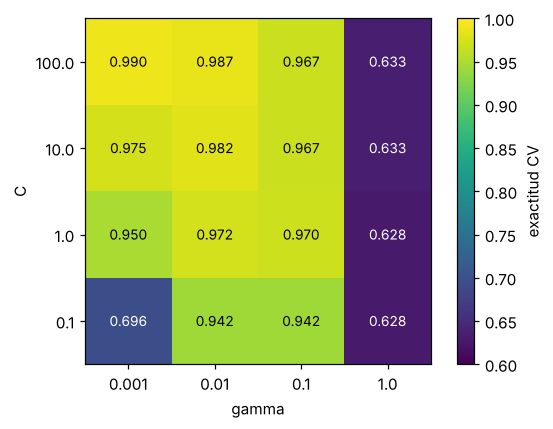

In [13]:
grilla = {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [1e-3, 1e-2, 1e-1, 1]}     # <-- CAMBIA
pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
busqueda = GridSearchCV(pipe, grilla, cv=CV).fit(Xtr, ytr)
print('mejores parámetros:', busqueda.best_params_, '| exactitud CV =', round(busqueda.best_score_, 3))

tabla = pd.DataFrame(busqueda.cv_results_['mean_test_score'].reshape(len(grilla['svc__C']), len(grilla['svc__gamma'])),
                     index=grilla['svc__C'], columns=grilla['svc__gamma'])
fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(tabla.values, cmap='viridis', origin='lower', vmin=.6, vmax=1)
ax.set_xticks(range(tabla.shape[1])); ax.set_xticklabels(tabla.columns); ax.set_yticks(range(tabla.shape[0])); ax.set_yticklabels(tabla.index)
ax.set_xlabel('gamma'); ax.set_ylabel('C'); ax.grid(False)
for (i, j), v in np.ndenumerate(tabla.values):
    ax.text(j, i, f'{v:.3f}', ha='center', va='center', color='w' if v < .9 else 'k', fontsize=9)
plt.colorbar(im, label='exactitud CV'); plt.tight_layout(); plt.show()

**Qué observar.** Hay una zona amplia de valores buenos y una zona que colapsa a la línea base. Cuando el óptimo cae en el borde de la grilla, conviene ampliarla en esa dirección.

### 3-3. Evaluación final (una sola vez)
**Predicción.** ¿Será la exactitud en prueba mayor, igual o menor que la exactitud CV del mejor modelo? ¿Por qué?

In [14]:
mejor = busqueda.best_estimator_
pred = mejor.predict(Xte)
print(f'exactitud CV (mejor modelo):  {busqueda.best_score_:.3f}')
print(f'exactitud en prueba:          {accuracy_score(yte, pred):.3f}')
print(f'línea base:                   {np.bincount(yte).max()/len(yte):.3f}')
print(f'lineal con C=1 en prueba:     {modelos["lineal"].fit(Xtr, ytr).score(Xte, yte):.3f}')
print(classification_report(yte, pred, target_names=datos.target_names, digits=3))

exactitud CV (mejor modelo):  0.990
exactitud en prueba:          0.953
línea base:                   0.626
lineal con C=1 en prueba:     0.953
              precision    recall  f1-score   support

   malignant      0.952     0.922     0.937        64
      benign      0.954     0.972     0.963       107

    accuracy                          0.953       171
   macro avg      0.953     0.947     0.950       171
weighted avg      0.953     0.953     0.953       171



**Reflexión (5 min).**
1. ¿Por qué no se usó el conjunto de prueba para elegir entre el lineal y el RBF?
2. Si la exactitud en prueba difiere un poco de la CV, ¿qué fuentes de incertidumbre hay? (Pista: ¿cuántos casos tiene la prueba? ¿cuántas combinaciones se evaluaron?)
3. Resume en una frase el modelo que entregarías y cómo reportarías su desempeño.

---
### Resumen de la sesión
1. C, γ y el kernel controlan la flexibilidad: se ven en la frontera, el margen y los vectores soporte.
2. La exactitud no basta: hay que mirar cada tipo de error, y actuar con el umbral o con `class_weight`.
3. Los hiperparámetros se eligen con validación cruzada dentro de un `Pipeline`; el conjunto de prueba se usa una sola vez.